# tp-26: 走法ベクトル × レース質分析

## 設計思想
1. **真の個別タイム**: `time_sec - last_3f = 前半個別タイム` (比例推定でなく実値)
2. **馬の走法ベクトル**: 前後半ペース比 + コーナー特性 + 加速特性の6軸
3. **レース質ベクトル**: 各レースで「何の走法が着順と相関したか」
4. **コース/馬場 × レース質統計**: 条件別の傾向を事前把握
5. **種牡馬 × レース質分析**: 血統が走法に与える傾向
6. **相性スコア**: 馬の走法プロファイル × 推定レース質 → 特徴量

## 馬の走法6軸
| 軸 | 算出 | 方向 |
|---|---|---|
| `ts` | L3-1F最高速F時間 | 小=速 |
| `gc` | L5→最高速への転換鋭さ | 大=鋭 |
| `split_ratio` | 後半pace/前半pace (**真の個別値**) | 小=後半加速型 |
| `front_ratio` | C1/頭数 | 小=前方 |
| `shift_ratio` | (C末-C1)/頭数 | 負=前進 |
| `late_kick` | (estL2-estL1)/estL2 | 正=L1さらに加速 |

In [1]:
from pathlib import Path
import sys
sys.path.insert(0, str(Path('../../..').resolve()))

import ast
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
import matplotlib
try:
    matplotlib.rcParams['font.family'] = 'IPAexGothic'
except:
    pass
import warnings
warnings.filterwarnings('ignore')

ROOT    = Path('../../..').resolve()
LAP_DIR = ROOT / 'data/local/backup/tables_before_reexport_20261014'
LS_PATH = ROOT / 'data/local/modeling/training_pipeline/lapscores/lapscores.parquet'
OUT_DIR = ROOT / 'data/local/modeling/training_pipeline/race_quality'
OUT_DIR.mkdir(parents=True, exist_ok=True)
print('ROOT:', ROOT)

ROOT: /home/jovyan/work/keiba-vpn


## 1. データ読み込み
`race_result_flat` には `time_sec` があるので、前後半個別タイムが計算できる。

In [2]:
YEARS = ['2020','2021','2022','2023','2024','2025']

dfs = []
for y in YEARS:
    p = LAP_DIR / y / 'race_result_flat.parquet'
    if not p.exists():
        print(f'{y}: not found'); continue
    d = pd.read_parquet(p, columns=[
        'race_id','date','venue','surface','distance','grade','race_class',
        'track_condition','field_size','finish_position',
        'horse_id','horse_name','passing_order',
        'last_3f','time_sec','lap_times',
    ])
    d['year'] = y
    dfs.append(d)

raw = pd.concat(dfs, ignore_index=True)
for c in ['last_3f','time_sec','field_size','finish_position']:
    raw[c] = pd.to_numeric(raw[c], errors='coerce')

# layer_a から sire 情報取得
layer_a = pd.read_parquet(
    ROOT / 'data/local/modeling/training_pipeline/layer_a.parquet',
    columns=['race_id','horse_id','sire']
)
raw = raw.merge(layer_a, on=['race_id','horse_id'], how='left')

print(f'読み込み: {len(raw):,} rows, {raw["race_id"].nunique():,} races')
print(f'sire有効率: {raw["sire"].notna().mean():.1%}')

読み込み: 286,060 rows, 20,733 races
sire有効率: 99.2%


## 2. 走法ベクトル計算

### 2-1. ラップ展開 (race-level)

In [3]:

print('ラップ展開中...')

def safe_parse(s):
    if s is None or (isinstance(s, float) and np.isnan(s)):
        return []
    if isinstance(s, str):
        try:
            return ast.literal_eval(s)
        except:
            return []
    if isinstance(s, (list, tuple)):
        return list(s)
    return []

laps_list = [safe_parse(s) for s in raw['lap_times']]
raw['n_laps']      = [len(l) for l in laps_list]
raw['race_last3f'] = [sum(l[-3:]) if len(l) >= 3 else float('nan') for l in laps_list]
raw['lap_L1']      = [float(l[-1]) if len(l) >= 1 else float('nan') for l in laps_list]
raw['lap_L2']      = [float(l[-2]) if len(l) >= 2 else float('nan') for l in laps_list]
raw['lap_L3']      = [float(l[-3]) if len(l) >= 3 else float('nan') for l in laps_list]
raw['race_L5']     = [float(l[-5]) if len(l) >= 5 else float('nan') for l in laps_list]

scale = raw['last_3f'] / raw['race_last3f'].replace(0, float('nan'))
raw['est_L3'] = raw['lap_L3'] * scale
raw['est_L2'] = raw['lap_L2'] * scale
raw['est_L1'] = raw['lap_L1'] * scale

print(f'done  n_laps>0: {(raw["n_laps"]>0).mean():.1%}')


ラップ展開中...
done  n_laps>0: 97.0%


### 2-2. 真の前後半個別タイム (time_sec ベース)

In [4]:
# 前半区間 F数 = n_laps - 3
raw['front_n_f']      = (raw['n_laps'] - 3).clip(lower=1)
raw['first_half_sec'] = raw['time_sec'] - raw['last_3f']          # 真の個別前半タイム
raw['pace_front_pf']  = raw['first_half_sec'] / raw['front_n_f']  # 前半 per-furlong
raw['pace_back_pf']   = raw['last_3f'] / 3                         # 後半 per-furlong
raw['split_ratio']    = raw['pace_back_pf'] / raw['pace_front_pf'].replace(0, float('nan'))
# 1未満 = 後半が速い (差し型), 1超 = 前半が速い (逃げ先行型)

# レース内の split_ratio 偏差 (同レース内での相対的な前後半バランス)
raw['split_vs_race'] = raw['split_ratio'] - raw.groupby('race_id')['split_ratio'].transform('mean')

print('前後半比 (split_ratio) 統計:')
print(raw['split_ratio'].describe().round(4))
print('\n前後半比 < 1 = 後半加速型 (差し追い込み):')
print(f'  split_ratio<1: {(raw["split_ratio"]<1).mean():.1%}')
print(f'  split_ratio>1: {(raw["split_ratio"]>1).mean():.1%}')

前後半比 (split_ratio) 統計:
count    283673.0000
mean          1.1761
std          28.3351
min       -1700.0000
25%           0.9647
50%           1.0171
75%           1.0756
max        2140.0000
Name: split_ratio, dtype: float64

前後半比 < 1 = 後半加速型 (差し追い込み):
  split_ratio<1: 40.6%
  split_ratio>1: 58.1%


### 2-3. コーナー通過順パース

In [5]:
print('コーナー通過順パース中...')

def parse_passing(s, field_size):
    if not isinstance(s, str) or not s or pd.isna(field_size) or field_size <= 1:
        return (np.nan,) * 4
    try:
        corners = [int(x) for x in s.split('-')]
    except:
        return (np.nan,) * 4
    if not corners:
        return (np.nan,) * 4
    fs = float(field_size)
    C1     = corners[0]
    C_last = corners[-1]
    front_ratio = C1 / fs
    shift_ratio = (C_last - C1) / fs
    pos_consistency = float(np.std(corners)) / fs if len(corners) > 1 else 0.0
    n_corners = len(corners)
    return (front_ratio, shift_ratio, pos_consistency, n_corners)

parsed = [
    parse_passing(po, fs)
    for po, fs in zip(raw['passing_order'], raw['field_size'])
]
p_df = pd.DataFrame(parsed, columns=['front_ratio','shift_ratio','pos_consistency','n_corners'])
raw = pd.concat([raw, p_df], axis=1)

# late_kick: L1でさらに加速しているか
raw['late_kick'] = (raw['est_L2'] - raw['est_L1']) / raw['est_L2'].replace(0, float('nan'))

# TS/GC (tp-25から): ts_fastest_f, gc_raw をLSから取得
ls = pd.read_parquet(LS_PATH, columns=['race_id','horse_id','ts_fastest_f','gc_raw'])
raw = raw.merge(ls, on=['race_id','horse_id'], how='left')

print(f'走法ベクトル列完成 (front_ratio有効: {raw["front_ratio"].notna().mean():.1%})')

コーナー通過順パース中...
走法ベクトル列完成 (front_ratio有効: 96.0%)


### 2-4. 特性ベクトルのサマリと着順相関

In [6]:
VEC_COLS = ['ts_fastest_f','gc_raw','split_ratio','front_ratio','shift_ratio','late_kick']

valid = (
    raw[VEC_COLS].notna().all(axis=1) &
    (raw['field_size'] >= 4) &
    raw['finish_position'].notna() &
    (raw['n_laps'] >= 5)
)
df = raw[valid].copy().reset_index(drop=True)
print(f'有効行: {len(df):,} ({valid.mean():.1%})')

print('\n=== 各特性 vs 着順 Spearman相関 ===')
labels = {
    'ts_fastest_f': 'TS最高速F時間 (小=速)',
    'gc_raw':        'GC鋭さ (大=鋭)',
    'split_ratio':   '前後半比 (小=後半加速型)',
    'front_ratio':   '脚質 (小=前)',
    'shift_ratio':   'ポジション変化 (負=前進)',
    'late_kick':     'L1キック (正=加速)',
}
for col, lbl in labels.items():
    r, p = spearmanr(df[col], df['finish_position'])
    print(f'  {lbl:30s}: r={r:+.4f}  p={p:.1e}')

有効行: 266,648 (93.2%)

=== 各特性 vs 着順 Spearman相関 ===
  TS最高速F時間 (小=速)                : r=+0.2247  p=0.0e+00
  GC鋭さ (大=鋭)                    : r=-0.2248  p=0.0e+00
  前後半比 (小=後半加速型)                : r=+0.1990  p=0.0e+00
  脚質 (小=前)                      : r=+0.1707  p=0.0e+00
  ポジション変化 (負=前進)                : r=+0.2803  p=0.0e+00
  L1キック (正=加速)                  : r=+0.0005  p=7.9e-01


## 3. レース質ベクトルの計算

In [7]:
# late_kick はレース全体ラップから比例計算 → 全馬で同値 → レース質相関に使えない
# RQ_FEATS から除外し、horse VEC_COLS には残す
RQ_FEATS = [c for c in VEC_COLS if c != 'late_kick']
RQ_COLS  = [f'rq_{f}' for f in RQ_FEATS]

def race_quality_vec(grp):
    fin = grp['finish_position']
    if len(grp) < 5 or fin.isna().any():
        return pd.Series([np.nan]*len(RQ_COLS), index=RQ_COLS)
    res = {}
    for feat, col in zip(RQ_FEATS, RQ_COLS):
        vals = grp[feat]
        if vals.isna().any() or vals.std() < 1e-9:
            res[col] = np.nan
        else:
            r, _ = spearmanr(vals, fin)
            res[col] = float(r)
    return pd.Series(res)

print('レース質ベクトルを計算中...')
rq = df.groupby('race_id', group_keys=False).apply(race_quality_vec).reset_index()
rq_valid = rq.dropna(subset=RQ_COLS, how='any')
print(f'レース質ベクトル: {len(rq_valid):,} races (有効: {len(rq_valid)/len(rq):.1%})')
print(rq_valid[RQ_COLS].describe().round(3))

レース質ベクトルを計算中...
レース質ベクトル: 17,001 races (有効: 87.8%)
       rq_ts_fastest_f  rq_gc_raw  rq_split_ratio  rq_front_ratio  \
count        17001.000  17001.000       17001.000       17001.000   
mean             0.742     -0.742           0.494           0.237   
std              0.195      0.195           0.328           0.341   
min             -0.670     -1.000          -0.821          -0.955   
25%              0.650     -0.883           0.293           0.004   
50%              0.794     -0.794           0.564           0.262   
75%              0.883     -0.650           0.753           0.495   
max              1.000      0.670           1.000           1.000   

       rq_shift_ratio  
count       17001.000  
mean            0.300  
std             0.288  
min            -0.866  
25%             0.118  
50%             0.329  
75%             0.512  
max             0.965  


findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Fon

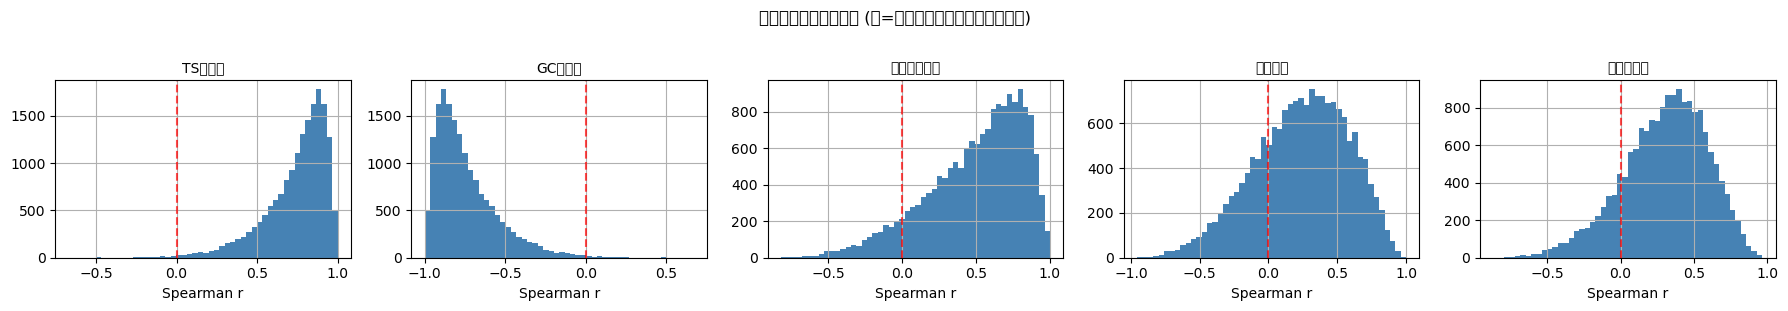

In [8]:
# レースメタ情報を付加
race_meta = df[['race_id','date','year','venue','surface','distance',
                'grade','race_class','track_condition']].drop_duplicates('race_id')
rq_meta = rq_valid.merge(race_meta, on='race_id', how='left')

# 各次元の分布可視化 (5軸: late_kickはレース共通値なのでRQ_FEATSから除外済み)
nice_names = ['TS要求度','GC要求度','後半加速要求','前残り度','前進型有利']
fig, axes = plt.subplots(1, 5, figsize=(18, 3))
for ax, col, name in zip(axes, RQ_COLS, nice_names):
    rq_meta[col].hist(bins=50, ax=ax, color='steelblue', edgecolor='none')
    ax.axvline(0, color='red', linestyle='--', alpha=0.7)
    ax.set_title(name, fontsize=10)
    ax.set_xlabel('Spearman r')
plt.suptitle('レース質ベクトル分布 (負=その特性が求められるレース)', y=1.02)
plt.tight_layout()
plt.savefig(OUT_DIR / 'rq_distributions.png', dpi=120, bbox_inches='tight')
plt.show()

## 4. レース質クラスタリング

rq_meta shape: (17001, 14)
rq_meta columns: ['race_id', 'rq_ts_fastest_f', 'rq_gc_raw', 'rq_split_ratio', 'rq_front_ratio', 'rq_shift_ratio', 'date', 'year', 'venue', 'surface', 'distance', 'grade', 'race_class', 'track_condition']
RQ_COLS NaN 率:
  rq_ts_fastest_f: 0.0%
  rq_gc_raw: 0.0%
  rq_split_ratio: 0.0%
  rq_front_ratio: 0.0%
  rq_shift_ratio: 0.0%

クラスタリング対象: 17,001 races (NaN除外後)


findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Fon

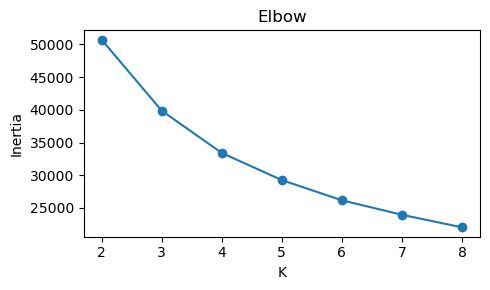

In [9]:

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

print('rq_meta shape:', rq_meta.shape)
print('rq_meta columns:', rq_meta.columns.tolist())
print('RQ_COLS NaN 率:')
for c in RQ_COLS:
    if c in rq_meta.columns:
        print(f'  {c}: {rq_meta[c].isna().mean():.1%}')
    else:
        print(f'  {c}: NOT FOUND')

rq_clean = rq_meta.dropna(subset=[c for c in RQ_COLS if c in rq_meta.columns]).copy().reset_index(drop=True)
print(f'\nクラスタリング対象: {len(rq_clean):,} races (NaN除外後)')

valid_rq_cols = [c for c in RQ_COLS if c in rq_clean.columns]
X = rq_clean[valid_rq_cols].values
scaler = StandardScaler()
X_sc   = scaler.fit_transform(X)

# Elbow
inertias = [KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_sc).inertia_ for k in range(2,9)]
plt.figure(figsize=(5,3))
plt.plot(range(2,9), inertias, 'o-')
plt.xlabel('K'); plt.ylabel('Inertia'); plt.title('Elbow')
plt.tight_layout()
plt.savefig(OUT_DIR / 'elbow.png', dpi=100)
plt.show()


In [10]:

K = 5
km = KMeans(n_clusters=K, random_state=42, n_init=20)
rq_clean['rq_type'] = km.fit_predict(X_sc)

# クラスタ重心
centers = pd.DataFrame(scaler.inverse_transform(km.cluster_centers_), columns=RQ_COLS)
centers.index.name = 'type'

def label_type(row):
    tags = []
    if row['rq_ts_fastest_f']  < -0.20: tags.append('TS要求')
    if row['rq_split_ratio']   < -0.10: tags.append('差し有利')
    if row['rq_split_ratio']   >  0.10: tags.append('前残り')
    if row['rq_front_ratio']   < -0.10: tags.append('前込み')
    if row['rq_gc_raw']        < -0.15: tags.append('GC要求')
    return ' + '.join(tags) if tags else '標準型'

centers['レース質タイプ'] = centers.apply(label_type, axis=1)
print('=== クラスタ重心 (K=5) ===')
print(centers[['レース質タイプ'] + RQ_COLS].round(3).to_string())
print()
print('クラスタ別レース数:', rq_clean['rq_type'].value_counts().sort_index().to_dict())

# rq_meta にクラスタを付加 (rq_clean は rq_meta のサブセット)
rq_meta = rq_meta.merge(rq_clean[['race_id','rq_type']], on='race_id', how='left')


=== クラスタ重心 (K=5) ===
               レース質タイプ  rq_ts_fastest_f  rq_gc_raw  rq_split_ratio  rq_front_ratio  rq_shift_ratio
type                                                                                              
0           前残り + GC要求            0.808     -0.808           0.625           0.195          -0.108
1           前残り + GC要求            0.858     -0.858           0.631           0.437           0.364
2          差し有利 + GC要求            0.293     -0.293          -0.111           0.515           0.163
3     前残り + 前込み + GC要求            0.860     -0.860           0.745          -0.150           0.530
4           前残り + GC要求            0.619     -0.619           0.223           0.380           0.283

クラスタ別レース数: {0: 2541, 1: 4198, 2: 1515, 3: 4540, 4: 4207}


findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Fon

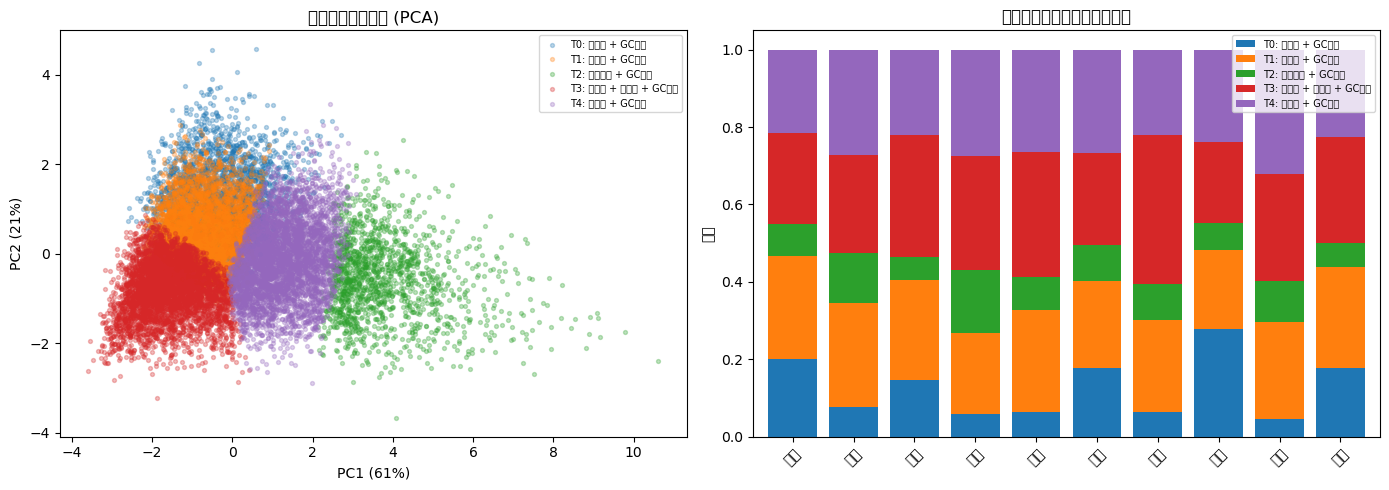

In [11]:

# PCA 2D可視化
pca = PCA(n_components=2, random_state=42)
X2  = pca.fit_transform(X_sc)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = plt.cm.tab10.colors

ax = axes[0]
for k in range(K):
    m = rq_clean['rq_type'] == k
    lbl = f'T{k}: {centers.loc[k,"レース質タイプ"]}'
    ax.scatter(X2[m,0], X2[m,1], c=[colors[k]], alpha=0.3, s=8, label=lbl)
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.0%})')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.0%})')
ax.set_title('レース質クラスタ (PCA)')
ax.legend(fontsize=7, loc='upper right')

# 競馬場別レース質タイプ分布
ax2 = axes[1]
venue_dist = rq_meta.dropna(subset=['rq_type']).groupby(['venue','rq_type'])['race_id'].count().unstack(fill_value=0)
venue_pct  = venue_dist.div(venue_dist.sum(axis=1), axis=0)
# K列あることを保証
for k in range(K):
    if k not in venue_pct.columns:
        venue_pct[k] = 0
venue_pct = venue_pct[[k for k in range(K)]]
venue_pct.plot(kind='bar', stacked=True, ax=ax2, color=colors[:K], width=0.8)
ax2.set_title('競馬場別レース質タイプ分布')
ax2.set_xlabel('')
ax2.set_ylabel('比率')
ax2.legend([f'T{k}: {centers.loc[k,"レース質タイプ"]}' for k in range(K)], fontsize=7, loc='upper right')
ax2.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig(OUT_DIR / 'rq_clusters.png', dpi=120, bbox_inches='tight')
plt.show()


## 5. コース別レース質統計
条件 (コース × 距離 × 馬場) ごとの平均レース質ベクトルを計算する。

In [12]:
# コース × 距離 × 馬場 × track_condition
cond_key  = ['venue','distance','surface','track_condition']
course_key = ['venue','distance','surface']

def build_course_stats(df_rq, key):
    grp = df_rq.groupby(key)
    mean = grp[RQ_COLS].mean().round(4)
    std  = grp[RQ_COLS].std().round(4).add_suffix('_std')
    n    = grp['race_id'].count().rename('n_races')
    dom  = grp['rq_type'].agg(lambda x: x.value_counts().idxmax()).rename('dominant_rq_type')
    return pd.concat([mean, std, n, dom], axis=1).reset_index()

cond_stats  = build_course_stats(rq_meta, cond_key)
course_stats = build_course_stats(rq_meta, course_key)

cond_stats   = cond_stats[cond_stats['n_races'] >= 3]
course_stats = course_stats[course_stats['n_races'] >= 5]

print(f'条件別レース質 (馬場込): {len(cond_stats):,} 件')
print(f'コース別レース質: {len(course_stats):,} 件')

print('\n=== TS要求が最も高いコース TOP10 ===')
ts_top = course_stats.nsmallest(10, 'rq_ts_fastest_f')[
    course_key + ['rq_ts_fastest_f','rq_split_ratio','rq_front_ratio','n_races','dominant_rq_type']
]
print(ts_top.to_string(index=False))

条件別レース質 (馬場込): 314 件
コース別レース質: 94 件

=== TS要求が最も高いコース TOP10 ===
venue  distance surface  rq_ts_fastest_f  rq_split_ratio  rq_front_ratio  n_races  dominant_rq_type
   中山      1200       芝           0.5316          0.1208          0.3077      179                 2
   新潟      1200       芝           0.5574          0.1328          0.3394       91                 2
   中京      1200       芝           0.5601          0.1587          0.2841      119                 4
   京都      1200       芝           0.5677          0.2190          0.2266       69                 4
   函館      1200       芝           0.5718          0.1886          0.2721      203                 4
   札幌      1200       芝           0.5880          0.2285          0.2908      130                 4
   阪神      1200       芝           0.6019          0.2021          0.3201      107                 4
   函館      1000     ダート           0.6046         -0.0542          0.5451       94                 4
   福島      1150     ダート           0.

In [13]:
print('=== 前残り傾向が最も強いコース TOP10 ===')
fr_top = course_stats.nsmallest(10, 'rq_split_ratio')[
    course_key + ['rq_split_ratio','rq_front_ratio','rq_ts_fastest_f','n_races']
]
print(fr_top.to_string(index=False))

print('\n=== 差し有利が最も強いコース TOP10 ===')
diff_top = course_stats.nlargest(10, 'rq_split_ratio')[
    course_key + ['rq_split_ratio','rq_front_ratio','rq_ts_fastest_f','n_races']
]
print(diff_top.to_string(index=False))

=== 前残り傾向が最も強いコース TOP10 ===
venue  distance surface  rq_split_ratio  rq_front_ratio  rq_ts_fastest_f  n_races
   函館      1000     ダート         -0.0542          0.5451           0.6046       94
   小倉      1000     ダート          0.0029          0.4945           0.6388      172
   福島      1150     ダート          0.0657          0.4760           0.6108      167
   中山      1200       芝          0.1208          0.3077           0.5316      179
   札幌      1000     ダート          0.1305          0.3720           0.6738       89
   新潟      1200       芝          0.1328          0.3394           0.5574       91
   中京      1200       芝          0.1587          0.2841           0.5601      119
   中山      1200     ダート          0.1691          0.3938           0.6399      674
   函館      1200       芝          0.1886          0.2721           0.5718      203
   新潟      1200     ダート          0.1915          0.3873           0.6607      320

=== 差し有利が最も強いコース TOP10 ===
venue  distance surface  rq_split_ratio  r

## 6. 種牡馬 × レース質分析
各種牡馬の産駒の走法ベクトル傾向と、得意なレース質タイプを分析する。

In [14]:
# 種牡馬別の走法プロファイル (全馬の平均)
sire_df = df[df['sire'].notna()].copy()

sire_profile = sire_df.groupby('sire').agg(
    n_runs        =('horse_id', 'count'),
    n_horses      =('horse_id', 'nunique'),
    ts_avg        =('ts_fastest_f', 'mean'),
    split_avg     =('split_ratio', 'mean'),
    front_avg     =('front_ratio', 'mean'),
    shift_avg     =('shift_ratio', 'mean'),
    late_kick_avg =('late_kick', 'mean'),
    gc_avg        =('gc_raw', 'mean'),
    win_rate      =('finish_position', lambda x: (x==1).mean()),
    top3_rate     =('finish_position', lambda x: (x<=3).mean()),
).reset_index()

# 十分なサンプルがある種牡馬のみ (50走以上)
sire_profile = sire_profile[sire_profile['n_runs'] >= 50].copy()
print(f'対象種牡馬: {len(sire_profile):,} 頭')

# 種牡馬別レース質タイプ好成績率
sire_rq = sire_df.merge(rq_meta[['race_id','rq_type']], on='race_id', how='left')
sire_rq_perf = sire_rq.groupby(['sire','rq_type']).agg(
    n=('finish_position','count'),
    top3_rate=('finish_position', lambda x: (x<=3).mean())
).reset_index()
print('\n種牡馬 × レース質タイプ別 複勝率 (サンプル):')
print(sire_rq_perf.head(20).to_string(index=False))

対象種牡馬: 1 頭

種牡馬 × レース質タイプ別 複勝率 (サンプル):
sire  rq_type     n  top3_rate
          0.0 33667   0.226513
          1.0 57411   0.219453
          2.0 21785   0.208951
          3.0 61292   0.222297
          4.0 60921   0.207416


In [15]:
# 各種牡馬の得意レース質タイプを特定
sire_best_rq = sire_rq_perf[sire_rq_perf['n'] >= 10].copy()
# 同じ種牡馬の中で最も複勝率が高いレース質タイプ
sire_best_rq = sire_best_rq.loc[
    sire_best_rq.groupby('sire')['top3_rate'].idxmax()
].rename(columns={'rq_type':'best_rq_type','top3_rate':'best_rq_top3','n':'best_rq_n'})
sire_best_rq['best_rq_label'] = sire_best_rq['best_rq_type'].map(
    {k: centers.loc[k,'レース質タイプ'] for k in range(K)}
)

sire_profile = sire_profile.merge(
    sire_best_rq[['sire','best_rq_type','best_rq_top3','best_rq_label']],
    on='sire', how='left'
)

print('=== 種牡馬 走法プロファイル TOP (split_ratio で差し型順) ===')
cols_show = ['sire','n_runs','split_avg','front_avg','ts_avg','gc_avg','best_rq_label','best_rq_top3']
print(sire_profile.nsmallest(20,'split_avg')[cols_show].round(3).to_string(index=False))

=== 種牡馬 走法プロファイル TOP (split_ratio で差し型順) ===
sire  n_runs  split_avg  front_avg  ts_avg  gc_avg best_rq_label  best_rq_top3
      266641      1.248      1.011  13.971  -0.135    前残り + GC要求         0.227


findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Fon

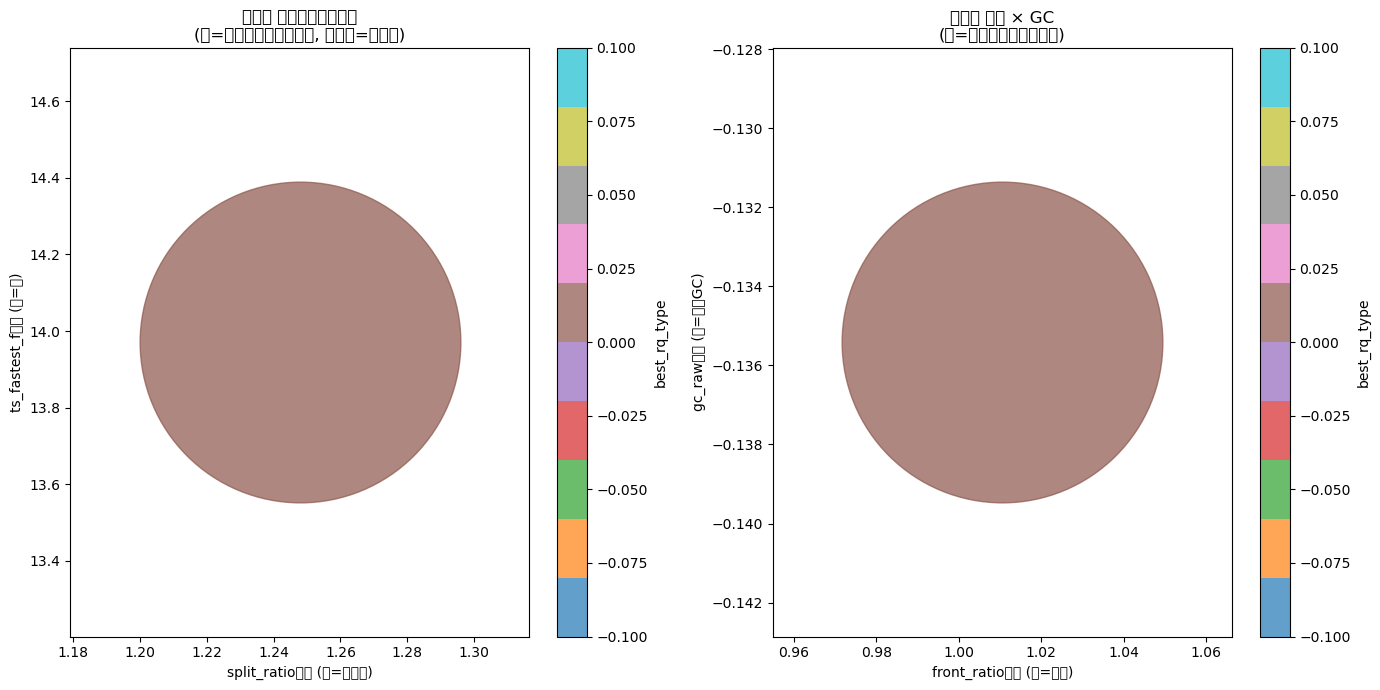

In [16]:
# 種牡馬プロファイルを可視化
top_sires = sire_profile.nlargest(40, 'n_runs').copy()

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

ax = axes[0]
sc = ax.scatter(
    top_sires['split_avg'],
    top_sires['ts_avg'],
    c=top_sires['best_rq_type'],
    cmap='tab10', s=top_sires['n_runs']/5, alpha=0.7
)
for _, row in top_sires.iterrows():
    ax.annotate(row['sire'][:8], (row['split_avg'], row['ts_avg']),
                fontsize=6, alpha=0.8)
ax.set_xlabel('split_ratio平均 (小=差し型)')
ax.set_ylabel('ts_fastest_f平均 (小=速)')
ax.set_title('種牡馬 走法プロファイル\n(色=得意レース質タイプ, サイズ=出走数)')
plt.colorbar(sc, ax=ax, label='best_rq_type')

ax2 = axes[1]
sc2 = ax2.scatter(
    top_sires['front_avg'],
    top_sires['gc_avg'],
    c=top_sires['best_rq_type'],
    cmap='tab10', s=top_sires['n_runs']/5, alpha=0.7
)
for _, row in top_sires.iterrows():
    ax2.annotate(row['sire'][:8], (row['front_avg'], row['gc_avg']),
                 fontsize=6, alpha=0.8)
ax2.set_xlabel('front_ratio平均 (小=前方)')
ax2.set_ylabel('gc_raw平均 (大=鋭いGC)')
ax2.set_title('種牡馬 脚質 × GC\n(色=得意レース質タイプ)')
plt.colorbar(sc2, ax=ax2, label='best_rq_type')

plt.tight_layout()
plt.savefig(OUT_DIR / 'sire_profiles.png', dpi=120, bbox_inches='tight')
plt.show()

findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Font family 'IPAexGothic' not found.
findfont: Fon

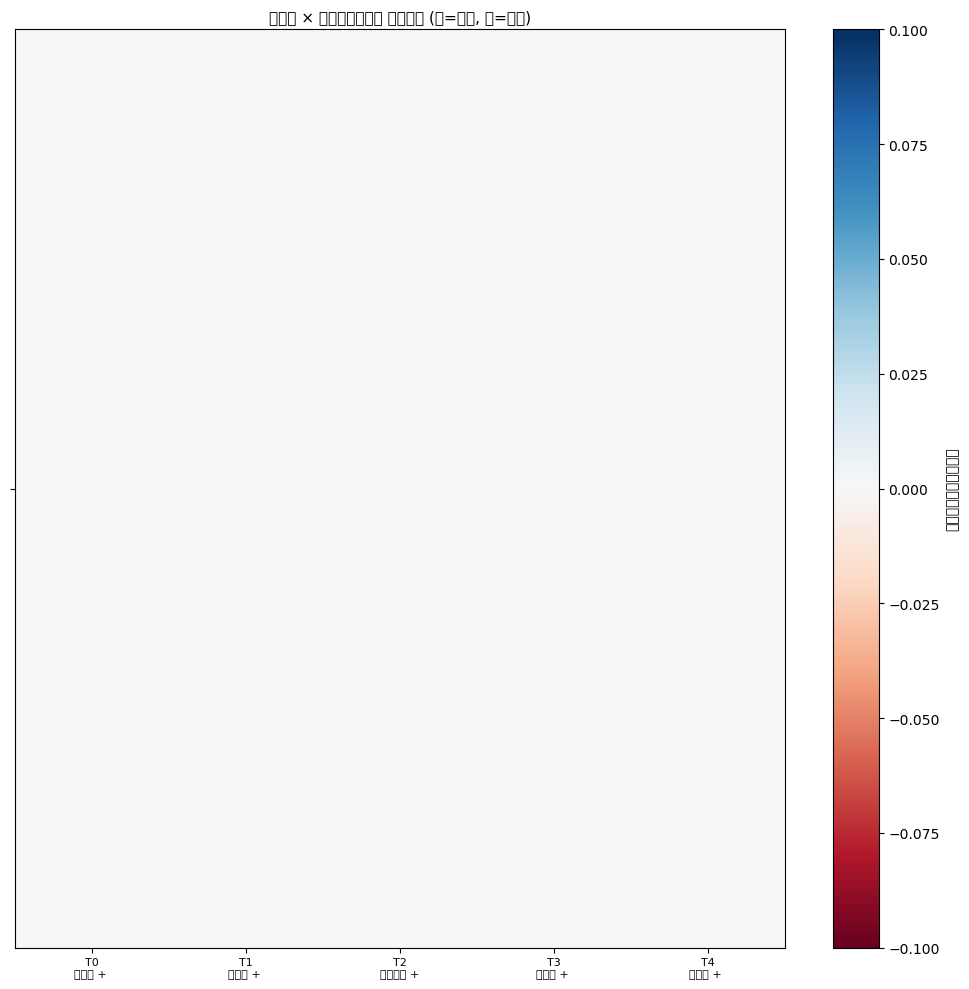

In [17]:
# 種牡馬ごとのレース質タイプ親和性マトリクス
top30_sires = sire_profile.nlargest(30,'n_runs')['sire'].tolist()
sire_rq_matrix = sire_rq_perf[
    (sire_rq_perf['sire'].isin(top30_sires)) & (sire_rq_perf['n'] >= 5)
].pivot_table(index='sire', columns='rq_type', values='top3_rate', fill_value=np.nan)

# 全体平均との差
overall_avg = sire_rq_perf.groupby('rq_type')['top3_rate'].mean()
sire_rq_diff = sire_rq_matrix.subtract(overall_avg, axis=1)

fig, ax = plt.subplots(figsize=(10, 10))
im = ax.imshow(sire_rq_diff.values, cmap='RdBu', vmin=-0.1, vmax=0.1, aspect='auto')
ax.set_xticks(range(K))
ax.set_xticklabels([f'T{k}\n{centers.loc[k,"レース質タイプ"][:6]}' for k in range(K)], fontsize=8)
ax.set_yticks(range(len(sire_rq_diff)))
ax.set_yticklabels(sire_rq_diff.index, fontsize=8)
plt.colorbar(im, ax=ax, label='全体平均との複勝率差')
ax.set_title('種牡馬 × レース質タイプ 複勝率差 (赤=得意, 青=苦手)', fontsize=11)
plt.tight_layout()
plt.savefig(OUT_DIR / 'sire_rq_matrix.png', dpi=120, bbox_inches='tight')
plt.show()

## 7. 馬の走法プロファイル集計 + 相性スコア

In [18]:
# 馬ごとの時系列プロファイル
prof_df = df[['race_id','horse_id','date','year'] + VEC_COLS].copy()
prof_df['date'] = pd.to_datetime(prof_df['date'])
prof_df = prof_df.sort_values(['horse_id','date']).reset_index(drop=True)

for col in VEC_COLS:
    for w in [3, 5]:
        prof_df[f'{col}_avg{w}'] = (
            prof_df.groupby('horse_id')[col]
            .transform(lambda x: x.shift(1).rolling(w, min_periods=1).mean())
        )
    prof_df[f'{col}_last1'] = (
        prof_df.groupby('horse_id')[col].transform(lambda x: x.shift(1))
    )

prof_feat_cols = [f'{c}_{s}' for c in VEC_COLS for s in ['avg3','avg5','last1']]
print(f'プロファイル特徴量: {len(prof_feat_cols)}列')

プロファイル特徴量: 18列


In [19]:
# 推定レース質 (コース条件から)
race_info = df[['race_id','venue','distance','surface','track_condition']].drop_duplicates('race_id')

def attach_exp_rq(race_df, cond_df, course_df):
    # 馬場込みで検索、なければコースのみ
    exp_cols = {c: f'exp_{c}' for c in RQ_COLS}
    merged = race_df.merge(
        cond_df[cond_key + RQ_COLS].rename(columns=exp_cols), on=cond_key, how='left'
    )
    miss = merged[f'exp_{RQ_COLS[0]}'].isna()
    backup = race_df.merge(
        course_df[course_key + RQ_COLS].rename(columns=exp_cols), on=course_key, how='left'
    )
    for c in RQ_COLS:
        ec = f'exp_{c}'
        merged.loc[miss, ec] = backup.loc[miss, ec].values
    return merged

race_exp = attach_exp_rq(race_info, cond_stats[cond_key + RQ_COLS], course_stats[course_key + RQ_COLS])
exp_rq_cols = [f'exp_{c}' for c in RQ_COLS]
hit_rate = race_exp[exp_rq_cols[0]].notna().mean()
print(f'推定レース質マッチ率: {hit_rate:.1%}')

推定レース質マッチ率: 99.3%


In [20]:
# 相性スコア = 馬の走法プロファイル(RQ_FEATS軸) × 推定レース質の内積
# late_kickはRQ_FEATSに含まれないので5軸で計算
compat = prof_df[['race_id','horse_id','date','year'] + [f'{c}_avg3' for c in VEC_COLS]].copy()
compat = compat.merge(race_exp[['race_id'] + exp_rq_cols], on='race_id', how='left')
compat = compat.merge(df[['race_id','horse_id','finish_position']].drop_duplicates(), on=['race_id','horse_id'], how='left')

# RQ_FEATS の5軸のみで内積 (late_kickはレース共通値なので除外)
# ts_fastest_f: 小=速 → 好 → *(-1)
# gc_raw: 大=鋭 → 好
# split_ratio: 小=差し型 → exp_rq_split_ratio が負のとき好相性
# front_ratio: 小=前 → exp_rq_front_ratio が負のとき好相性
# shift_ratio: 負=前進型 → 好
horse_sign = np.array([-1, 1, -1, -1, -1])   # 5軸: 大=良い方向に揃え
exp_sign   = np.array([-1, -1, -1, -1, -1])  # rqは負=その特性が有利

hv_cols = [f'{c}_avg3' for c in RQ_FEATS]
ev_cols = exp_rq_cols

H = compat[hv_cols].fillna(compat[hv_cols].median()).values * horse_sign
E = compat[ev_cols].fillna(0).values                         * exp_sign

# Z正規化して内積
H_z = (H - np.nanmean(H, axis=0)) / (np.nanstd(H, axis=0) + 1e-9)
E_z = (E - np.nanmean(E, axis=0)) / (np.nanstd(E, axis=0) + 1e-9)
compat['rq_compat'] = (H_z * E_z).sum(axis=1)

# レース内偏差値化
mu = compat.groupby('race_id')['rq_compat'].transform('mean')
sd = compat.groupby('race_id')['rq_compat'].transform('std').fillna(1).replace(0, 1)
compat['rq_compat_dev'] = (compat['rq_compat'] - mu) / sd * 10 + 50

ev = compat.dropna(subset=['finish_position','rq_compat_dev'])
r, p = spearmanr(ev['rq_compat_dev'], ev['finish_position'])
print(f'相性スコア(偏差値) Spearman vs 着順: r={r:.4f}  p={p:.2e}')

print('\n相性スコア上位 k% の複勝率:')
for pct in [50, 70, 80, 90]:
    thr = ev['rq_compat_dev'].quantile(pct/100)
    sel = ev[ev['rq_compat_dev'] >= thr]
    wr  = (sel['finish_position'] == 1).mean()
    t3  = (sel['finish_position'] <= 3).mean()
    print(f'  上位{100-pct:2d}%: 勝率={wr:.3f}  複勝率={t3:.3f}  ({len(sel):,}頭)')
b_w = (ev['finish_position'] == 1).mean()
b_t = (ev['finish_position'] <= 3).mean()
print(f'  ベースライン: 勝率={b_w:.3f}  複勝率={b_t:.3f}')

相性スコア(偏差値) Spearman vs 着順: r=0.0228  p=5.39e-32

相性スコア上位 k% の複勝率:
  上位50%: 勝率=0.070  複勝率=0.212  (145,853頭)
  上位30%: 勝率=0.066  複勝率=0.204  (79,995頭)
  上位20%: 勝率=0.064  複勝率=0.200  (53,330頭)
  上位10%: 勝率=0.059  複勝率=0.189  (26,665頭)
  ベースライン: 勝率=0.073  複勝率=0.218


## 8. 保存

In [21]:
# ① レースごとのレース質ベクトル
rq_meta.to_parquet(OUT_DIR / 'race_quality_vec.parquet', index=False)

# ② コース別レース質統計
course_stats.to_parquet(OUT_DIR / 'course_rq.parquet', index=False)
cond_stats.to_parquet(OUT_DIR / 'cond_rq.parquet', index=False)

# ③ 種牡馬プロファイル
sire_profile.to_parquet(OUT_DIR / 'sire_profile.parquet', index=False)

# ④ 馬の走法プロファイル特徴量 + 相性スコア
compat_save = compat[['race_id','horse_id','rq_compat','rq_compat_dev']]
final = prof_df[['race_id','horse_id','date','year'] + prof_feat_cols].merge(
    compat_save, on=['race_id','horse_id'], how='left'
)
final.to_parquet(OUT_DIR / 'horse_rq_features.parquet', index=False)

print('保存完了:')
for f in sorted(OUT_DIR.glob('*.parquet')):
    print(f'  {f.name}: {f.stat().st_size/1e6:.1f} MB')

print(f'\n=== 最終サマリ ===')
print(f'走法ベクトル軸数: {len(VEC_COLS)}')
print(f'レース質ベクトル: {len(rq_meta):,} レース  クラスタ数: {K}')
print(f'コース別統計: {len(cond_stats):,} 条件 / {len(course_stats):,} コース')
print(f'種牡馬プロファイル: {len(sire_profile):,} 頭')
print(f'馬の走法特徴量: {final.shape}')
print(f'相性スコア Spearman r={r:.4f}')

保存完了:
  cond_rq.parquet: 0.0 MB
  course_rq.parquet: 0.0 MB
  horse_rq_features.parquet: 30.8 MB
  race_quality_vec.parquet: 0.7 MB
  sire_profile.parquet: 0.0 MB

=== 最終サマリ ===
走法ベクトル軸数: 6
レース質ベクトル: 17,001 レース  クラスタ数: 5
コース別統計: 314 条件 / 94 コース
種牡馬プロファイル: 1 頭
馬の走法特徴量: (266648, 24)
相性スコア Spearman r=0.0228
